[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aaxhirrr/mat-422-fall-2026/blob/main/HW3.4/HW3_4_logistic_regression.ipynb)

# homework 3.4: logistic regression

Aashir Javed | MAT 422

A straight-line prediction can be any real number, which is a problem if we want a probability. Logistic regression keeps the linear score but passes it through a sigmoid so the result stays between zero and one. Here I check how that works, fit a small model, and compare its predictions with labels it did not train on.

The examples cover sigmoid probabilities, likelihood and cross-entropy, gradient descent, and a decision boundary. We can run everything with **Runtime > Run all** in Colab. There are no data files to download.

score: [-4 -2  0  2  4]
probability: [0.018  0.1192 0.5    0.8808 0.982 ]


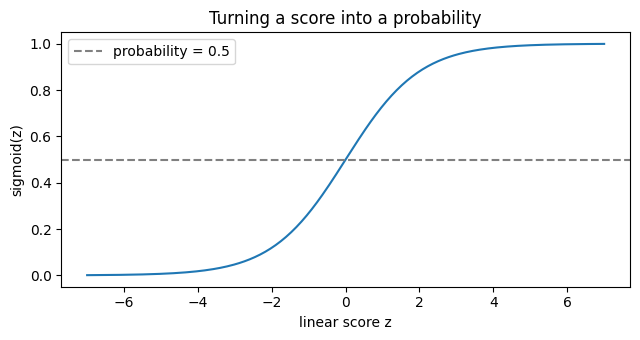

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

def sigmoid(z):
    # This is the same sigmoid, written to avoid overflow for large scores.
    return np.exp(-np.logaddexp(0, -np.asarray(z, dtype=float)))

scores = np.array([-4, -2, 0, 2, 4])
print("score:", scores)
print("probability:", sigmoid(scores))

z_grid = np.linspace(-7, 7, 300)
plt.figure(figsize=(6.5, 3.5))
plt.plot(z_grid, sigmoid(z_grid))
plt.axhline(0.5, linestyle="--", color="gray", label="probability = 0.5")
plt.xlabel("linear score z")
plt.ylabel("sigmoid(z)")
plt.title("Turning a score into a probability")
plt.legend()
plt.tight_layout()
plt.show()

## from a score to a probability

For a binary label $y\in\{0,1\}$, the model is

$$z=b+w_1x_1+w_2x_2,\qquad p=P(y=1\mid\mathbf{x})=\sigma(z)=\frac{1}{1+e^{-z}}.$$

The other class has probability $1-p$. At score zero, both classes have probability $0.5$. The printed values also show that changing the score from $-2$ to $2$ moves the probability from about $0.119$ to $0.881$. A high score means the model favors class 1, not that the label is certain.

The odds and log-odds connect the probability back to the linear score:

$$\frac{p}{1-p}=e^z,\qquad \log\left(\frac{p}{1-p}\right)=z,\qquad \sigma'(z)=\sigma(z)(1-\sigma(z)).$$

Holding the other feature fixed, a one-unit increase in $x_j$ multiplies the odds by $e^{w_j}$. It does not add a fixed amount to the probability.

## a small dataset

We can use two simulated measurements and a binary outcome to keep the example easy to inspect. I generate the labels from known probabilities, but the fitted model only gets the measurements and labels. Sampling labels means even a high-probability point can land in class 0. These are made-up observations, not evidence about real people or events.

The first 120 shuffled observations are used for training and the remaining 40 are held out. The scaling uses only the training mean and standard deviation, so the test set does not help prepare the model.

training class counts [0, 1]: [78 42]
test class counts [0, 1]: [24 16]


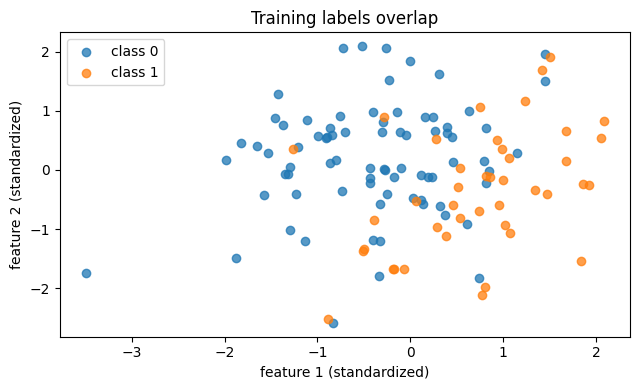

In [2]:
rng = np.random.default_rng(422)
features = rng.normal(size=(160, 2))
true_probability = sigmoid(-0.3 + 1.6*features[:, 0] - 1.1*features[:, 1])
labels = rng.binomial(1, true_probability)
order = rng.permutation(len(labels))
train_indices, test_indices = order[:120], order[120:]

train_mean = features[train_indices].mean(axis=0)
train_std = features[train_indices].std(axis=0)
train_features = (features[train_indices] - train_mean) / train_std
test_features = (features[test_indices] - train_mean) / train_std
# A column of ones lets the intercept use the same update as the weights.
X_train = np.column_stack([np.ones(120), train_features])
X_test = np.column_stack([np.ones(40), test_features])
y_train, y_test = labels[train_indices], labels[test_indices]
print("training class counts [0, 1]:", np.bincount(y_train, minlength=2))
print("test class counts [0, 1]:", np.bincount(y_test, minlength=2))

plt.figure(figsize=(6.5, 4))
for label, color in [(0, "tab:blue"), (1, "tab:orange")]:
    selected = y_train == label
    plt.scatter(train_features[selected, 0], train_features[selected, 1],
                color=color, alpha=0.75, label=f"class {label}")
plt.xlabel("feature 1 (standardized)")
plt.ylabel("feature 2 (standardized)")
plt.title("Training labels overlap")
plt.legend()
plt.tight_layout()
plt.show()

The classes overlap rather than forming two perfectly separate groups. That is expected because the labels were sampled from probabilities. The aim is to learn the probability pattern, not force every point onto the correct side of a line.

## likelihood and the loss

Assuming independent observations conditional on their features, each label has Bernoulli probability $p_i^{y_i}(1-p_i)^{1-y_i}$. The likelihood is their product:

$$L(\boldsymbol\theta)=\prod_{i=1}^n p_i^{y_i}(1-p_i)^{1-y_i},\qquad
\boldsymbol\theta=(b,w_1,w_2)^T.$$

Maximizing the likelihood is equivalent to minimizing the average negative log-likelihood, also called binary cross-entropy:

$$J(\boldsymbol\theta)=-\frac1n\sum_{i=1}^n[y_i\log p_i+(1-y_i)\log(1-p_i)].$$

A confident wrong prediction costs more than an uncertain one. For example, when the true label is 1, predicting $0.1$ gives loss about $2.303$, while predicting $0.9$ gives about $0.105$.

For computation, the same per-point loss is $\log(1+e^{z_i})-y_i z_i$. `logaddexp` evaluates the first term without overflowing. This avoids taking the log of a probability rounded to zero.

In [3]:
def loss(theta, X, y):
    scores = X @ theta
    return np.mean(np.logaddexp(0, scores) - y*scores)

example_probabilities = np.array([0.1, 0.5, 0.9])
print("predicted probabilities:", example_probabilities)
print("loss if the label is 1:", -np.log(example_probabilities))
print("loss if the label is 0:", -np.log(1-example_probabilities))
print("starting training loss:", loss(np.zeros(3), X_train, y_train))

predicted probabilities: [0.1 0.5 0.9]
loss if the label is 1: [2.3026 0.6931 0.1054]
loss if the label is 0: [0.1054 0.6931 2.3026]
starting training loss: 0.6931471805599453


With all three parameters at zero, every prediction is $0.5$ and the loss is $\log 2$, about $0.693$. That gives us a starting point for the training loop.

## fitting the parameters

For one observation, differentiating the loss with respect to its score gives $p_i-y_i$. Applying the chain rule to $z_i=\mathbf{x}_i^T\boldsymbol\theta$ gives

$$\nabla J(\boldsymbol\theta)=\frac1n X^T(\mathbf{p}-\mathbf{y}),\qquad
\boldsymbol\theta_{k+1}=\boldsymbol\theta_k-\alpha\nabla J(\boldsymbol\theta_k).$$

Here $X$ includes the column of ones for the intercept. The Hessian is

$$\nabla^2 J=\frac1n X^T W X,\qquad W_{ii}=p_i(1-p_i)\ge0.$$

For any vector $\mathbf{v}$, $\mathbf{v}^T\nabla^2J\mathbf{v}=\sum_i W_{ii}(\mathbf{x}_i^T\mathbf{v})^2/n\ge0$, so the loss is convex. A finite stationary point is therefore a global minimizer. Convexity alone does not guarantee a finite solution: with perfectly separable data, unregularized logistic regression can keep increasing the weights while the loss approaches its infimum.

Since $p_i(1-p_i)\le1/4$, a gradient Lipschitz bound is $L=\|X\|_2^2/(4n)$. We can check that the learning rate $0.5$ is below $1/L$. The loop stops at a small gradient or at 5,000 updates, whichever comes first.

1/L bound: 3.6886; learning rate: 0.5


updates: 918
parameters [intercept, weight 1, weight 2]: [-1.206   2.1069 -1.1005]
final training loss: 0.401701
final gradient norm: 9.873e-09
odds multipliers for one standardized unit: [8.2227 0.3327]


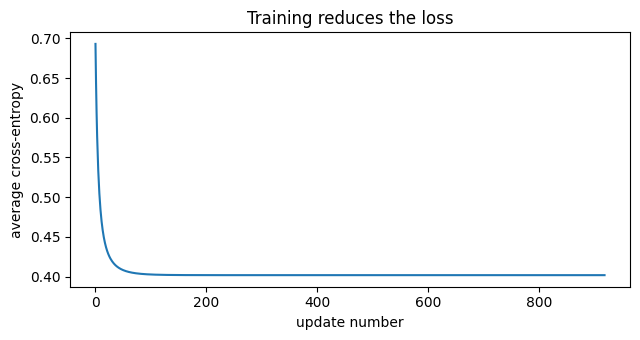

In [4]:
def gradient(theta, X, y):
    return X.T @ (sigmoid(X @ theta) - y) / len(y)

learning_rate = 0.5
L_bound = np.linalg.norm(X_train, 2)**2 / (4*len(y_train))
print(f"1/L bound: {1/L_bound:.4f}; learning rate: {learning_rate}")
theta = np.zeros(3)
loss_history = [loss(theta, X_train, y_train)]
for step in range(5000):
    grad = gradient(theta, X_train, y_train)
    if np.linalg.norm(grad) < 1e-8:
        break
    theta = theta - learning_rate*grad
    loss_history.append(loss(theta, X_train, y_train))

print("updates:", len(loss_history)-1)
print("parameters [intercept, weight 1, weight 2]:", theta)
print(f"final training loss: {loss_history[-1]:.6f}")
print(f"final gradient norm: {np.linalg.norm(gradient(theta, X_train, y_train)):.3e}")
print("odds multipliers for one standardized unit:", np.exp(theta[1:]))

plt.figure(figsize=(6.5, 3.5))
plt.plot(loss_history)
plt.xlabel("update number")
plt.ylabel("average cross-entropy")
plt.title("Training reduces the loss")
plt.tight_layout()
plt.show()

The loop takes 918 updates, bringing the loss from about $0.693$ down to $0.402$. It levels out as the gradient becomes small. The fitted coefficient for feature 1 is positive and the coefficient for feature 2 is negative, matching the directions used to generate the data. The estimates do not have to equal the generating coefficients: we have a finite random sample, and the model uses standardized features.

The printed odds multipliers describe a one-standard-deviation increase in a feature, holding the other one fixed. For feature 1, the odds are multiplied by about $8.22$; for feature 2, they are multiplied by about $0.333$. These describe the fitted association, not a causal effect.

## predictions on held-out observations

The model produces probabilities first. To turn them into labels, we can predict class 1 when $p\ge0.5$. Since $\sigma(0)=0.5$, the decision boundary is

$$b+w_1x_1+w_2x_2=0.$$

That boundary is linear in the features even though the probability is not. The test labels below were not used in the updates. Accuracy counts correct labels, while test cross-entropy also takes the model's confidence into account. I compare both with a baseline that always predicts the training class-1 fraction.

test accuracy: 0.800; baseline: 0.600
test cross-entropy: 0.4777; baseline: 0.6784
confusion matrix (rows = actual, columns = predicted):
[[23  1]
 [ 7  9]]
first six: actual, probability, predicted
0  0.002  0
0  0.491  0
0  0.052  0
1  0.605  1
1  0.257  0
0  0.002  0


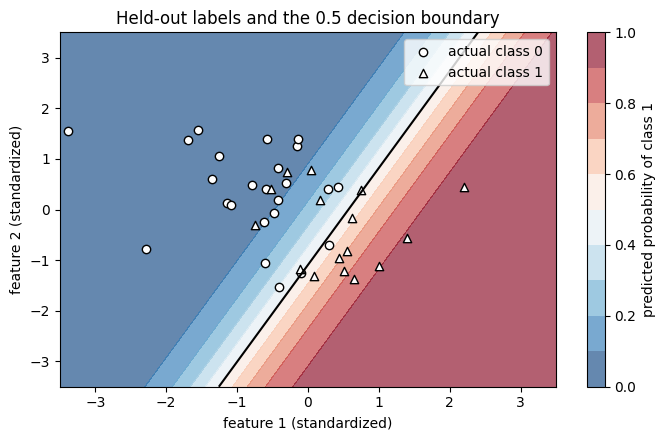

In [5]:
test_probabilities = sigmoid(X_test @ theta)
test_predictions = (test_probabilities >= 0.5).astype(int)
test_accuracy = np.mean(test_predictions == y_test)
test_loss = loss(theta, X_test, y_test)
baseline_probability = y_train.mean()
baseline_loss = -np.mean(y_test*np.log(baseline_probability)
                        + (1-y_test)*np.log(1-baseline_probability))
baseline_accuracy = np.mean(y_test == int(baseline_probability >= 0.5))
confusion = np.zeros((2, 2), dtype=int)
for actual, predicted in zip(y_test, test_predictions):
    confusion[actual, predicted] += 1

print(f"test accuracy: {test_accuracy:.3f}; baseline: {baseline_accuracy:.3f}")
print(f"test cross-entropy: {test_loss:.4f}; baseline: {baseline_loss:.4f}")
print("confusion matrix (rows = actual, columns = predicted):")
print(confusion)
print("first six: actual, probability, predicted")
for actual, probability, predicted in zip(y_test[:6], test_probabilities[:6], test_predictions[:6]):
    print(f"{actual}  {probability:.3f}  {predicted}")

xx, yy = np.meshgrid(np.linspace(-3.5, 3.5, 200), np.linspace(-3.5, 3.5, 200))
grid_probability = sigmoid(theta[0] + theta[1]*xx + theta[2]*yy)
plt.figure(figsize=(7, 4.5))
plt.contourf(xx, yy, grid_probability, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.65)
plt.colorbar(label="predicted probability of class 1")
plt.contour(xx, yy, grid_probability, levels=[0.5], colors="black", linewidths=1.5)
for label, marker in [(0, "o"), (1, "^")]:
    selected = y_test == label
    plt.scatter(test_features[selected, 0], test_features[selected, 1], marker=marker,
                color="white", edgecolors="black", label=f"actual class {label}")
plt.xlabel("feature 1 (standardized)")
plt.ylabel("feature 2 (standardized)")
plt.title("Held-out labels and the 0.5 decision boundary")
plt.legend()
plt.tight_layout()
plt.show()

The model gets 32 of the 40 held-out labels right, or $80\%$, compared with $60\%$ for the baseline. Test cross-entropy is also lower, about $0.478$ instead of $0.678$. The confusion matrix shows one false positive and seven false negatives. So the accuracy alone does not tell the whole story: at this threshold, more of the mistakes are missed positives.

The black line separates the two predicted classes, while the background shows that confidence changes gradually. Some held-out labels are on the wrong side of the line. That does not automatically mean the fitting code is broken: the generated labels are noisy, and a probability is not a guarantee. These results describe one small simulated test set, not a guarantee about future data.

A threshold of $0.5$ is a choice, not part of training the weights. Lowering it predicts class 1 more often. That can catch more actual positives, but it can also produce more false positives. We can check this tradeoff without fitting the model again. This is an illustration, not a way to tune a threshold on the test set; choosing one for deployment would need separate validation data and the costs of each error.

In [6]:
print("threshold  predicted positives  true positives  false positives")
for threshold in [0.3, 0.5, 0.7]:
    predicted = test_probabilities >= threshold
    true_positives = np.sum(predicted & (y_test == 1))
    false_positives = np.sum(predicted & (y_test == 0))
    print(f"{threshold:.1f}        {predicted.sum():2d}                   {true_positives:2d}              {false_positives:2d}")

threshold  predicted positives  true positives  false positives
0.3        15                   11               4
0.5        10                    9               1
0.7         6                    6               0


## checking the calculations

We can compare the analytical gradient with central finite differences at a nonzero parameter vector. I also check the two equivalent loss formulas, the Hessian, the split, and the training behavior. These are checks on this example, not a claim that logistic regression always beats a baseline on new data.

In [7]:
probe = np.array([0.2, -0.4, 0.7])
h = 1e-5
numerical_gradient = np.zeros(3)
for j in range(3):
    offset = np.zeros(3)
    offset[j] = h
    numerical_gradient[j] = (loss(probe+offset, X_train, y_train)
                             - loss(probe-offset, X_train, y_train)) / (2*h)
probe_p = sigmoid(X_train @ probe)
direct_loss = -np.mean(y_train*np.log(probe_p) + (1-y_train)*np.log(1-probe_p))
fitted_p = sigmoid(X_train @ theta)
hessian = X_train.T @ ((fitted_p*(1-fitted_p))[:, None]*X_train) / len(y_train)
print("gradient difference:", np.max(np.abs(numerical_gradient-gradient(probe, X_train, y_train))))
print("fitted Hessian eigenvalues:", np.linalg.eigvalsh(hessian))

checks = {
    "sigmoid at zero is one half": np.isclose(sigmoid(0), 0.5),
    "sigmoid symmetry holds": np.allclose(sigmoid(scores)+sigmoid(-scores), 1),
    "extreme scores stay finite": np.all(np.isfinite(sigmoid([-1000, 1000]))),
    "train and test sets are disjoint": len(np.intersect1d(train_indices, test_indices)) == 0,
    "training features are centered": np.allclose(train_features.mean(axis=0), 0),
    "both loss formulas agree": np.isclose(direct_loss, loss(probe, X_train, y_train)),
    "gradient matches finite differences": np.allclose(numerical_gradient, gradient(probe, X_train, y_train), atol=1e-7),
    "fitted Hessian is positive definite": np.all(np.linalg.eigvalsh(hessian) > 0),
    "learning rate satisfies the bound": learning_rate <= 1/L_bound,
    "training loss never increases": np.all(np.diff(loss_history) <= 1e-12),
    "gradient tolerance was reached": np.linalg.norm(gradient(theta, X_train, y_train)) < 1e-8,
    "test probabilities are in range": np.all((test_probabilities >= 0) & (test_probabilities <= 1)),
    "probability and score classifiers agree": np.array_equal(test_predictions, (X_test @ theta >= 0).astype(int)),
    "confusion matrix counts every test point": confusion.sum() == len(y_test),
}
for label, passed in checks.items():
    print(f"{label}: {bool(passed)}")
assert all(checks.values()), "one of the checks needs another look"

gradient difference: 5.2143289686057415e-12
fitted Hessian eigenvalues: [0.0325 0.1569 0.1579]
sigmoid at zero is one half: True
sigmoid symmetry holds: True
extreme scores stay finite: True
train and test sets are disjoint: True
training features are centered: True
both loss formulas agree: True
gradient matches finite differences: True
fitted Hessian is positive definite: True
learning rate satisfies the bound: True
training loss never increases: True
gradient tolerance was reached: True
test probabilities are in range: True
probability and score classifiers agree: True
confusion matrix counts every test point: True


## what I took from this

Logistic regression separates two questions: how likely is class 1, and what label should we assign? The sigmoid handles the probability, cross-entropy gives us a fitting objective, and gradient descent adjusts the coefficients. The threshold comes afterward. Looking at both the loss and the held-out labels is more useful than checking accuracy alone, especially when a wrong prediction is made with high confidence.

The examples include the formulas, saved plots, and numerical checks so we can follow the probability calculation through to the final predictions. The Open in Colab button at the top lets us rerun the whole notebook and try different values.

- AI use note: I had help from Codex in refining the code (not completely writing it), refining the latex of the report, and pushing it to GitHub. Other than that, the intial psuedocode/boilerplates, logic, and the report is still drafted by me. I ran every cell and reviewed the math and explanations before submitting.